2026297, Erick Henrique da Silva,

PREDICTING PREMIER LEAGUE MATCHES OUTCOMES

Github Link: https://github.com/2026297-cyber/Machine-Learning

Datasets: https://datahub.io/football/english-premier-league

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df1  = pd.read_csv("season-2526.csv")
df2  = pd.read_csv("season-2425.csv")
df3  = pd.read_csv("season-2324.csv")
df4  = pd.read_csv("season-2223.csv")
df5  = pd.read_csv("season-2122.csv")
df6  = pd.read_csv("season-2021.csv")
df7  = pd.read_csv("season-1920.csv")
df8  = pd.read_csv("season-1819.csv")
df9  = pd.read_csv("season-1718.csv")
df10 = pd.read_csv("season-1617.csv")

df = pd.concat([df1, df2, df3, df4, df5, df6, df7, df8, df9, df10])

DICTIONARY
- FTHG = Full Time Home Goals 
- FTAG = Full Time Away Goals 
- FTR  = Full Time Result - (Home = H, Away = A, Draw = D) - TARGET
- HTHG = Half Time Home Goals 
- HTAG = Half Time Away Goals 
- HTR  = Half Time Result 
- Referee = Match Referee
- HS   = Home Shots 
- AS   = Away Shots 
- HST  = Home Shots on Target 
- AST  = Away Shots on Target 
- HF   = Home Fouls 
- AF   = Away Fouls 
- HC   = Home Corners 
- AC   = Away Corners 
- HY   = Home Yellows 
- AY   = Away Yellows 
- HR   = Home Reds 
- AR   = Away Reds

This Dataset is the result of the last 10 Premier League seasons from 2016/17 to 2025/26. Each dataset has 380 rows and 22 columns, for a total 3800 rows. The model seeks to predict the match results using the statistics of these matches as shots, cornes and fouls.

Question: Which features most affect the results of a match?


In [3]:
df

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,...,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
0,2025-08-15,Liverpool,Bournemouth,4,2,H,1,0,H,A Taylor,...,10,3,7,10,6,7,1,2,0,0
1,2025-08-16,Aston Villa,Newcastle,0,0,D,0,0,D,C Pawson,...,3,3,13,11,3,6,1,1,1,0
2,2025-08-16,Brighton,Fulham,1,1,D,0,0,D,S Barrott,...,4,2,16,15,4,3,3,3,0,0
3,2025-08-16,Sunderland,West Ham,3,0,H,0,0,D,R Jones,...,5,4,8,10,5,7,0,1,0,0
4,2025-08-16,Tottenham,Burnley,3,0,H,1,0,H,M Oliver,...,6,4,14,8,6,5,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
375,2017-05-21,Liverpool,Middlesbrough,3,0,H,1,0,H,M Atkinson,...,10,3,13,8,3,3,0,1,0,0
376,2017-05-21,Man United,Crystal Palace,2,0,H,2,0,H,A Taylor,...,2,1,16,10,3,6,2,0,0,0
377,2017-05-21,Southampton,Stoke,0,1,A,0,0,D,L Probert,...,6,3,12,10,4,10,2,4,0,0
378,2017-05-21,Swansea,West Brom,2,1,H,0,1,A,M Dean,...,2,5,8,10,7,4,1,1,0,0


In [4]:
df.shape

(3800, 22)

In [5]:
df.describe()

,FTHG,FTAG,HTHG,HTAG,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
count,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000
mean,1.555263,1.279737,0.697895,0.564211,13.867105,11.480263,4.768158,4.023421,10.598158,10.868158,5.664474,4.687632,1.656579,1.850000,0.053947,0.061053
std,1.313304,1.207771,0.847582,0.780172,5.685582,5.060168,2.618839,2.362564,3.426335,3.562880,3.060554,2.796334,1.271598,1.311911,0.236196,0.244893
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000,0.000000,10.000000,8.000000,3.000000,2.000000,8.000000,8.000000,3.000000,3.000000,1.000000,1.000000,0.000000,0.000000
50%,1.000000,1.000000,0.000000,0.000000,13.000000,11.000000,4.000000,4.000000,10.000000,11.000000,5.000000,4.000000,2.000000,2.000000,0.000000,0.000000
75%,2.000000,2.000000,1.000000,1.000000,17.000000,15.000000,6.000000,5.000000,13.000000,13.000000,8.000000,6.000000,2.000000,3.000000,0.000000,0.000000
max,9.000000,9.000000,5.000000,5.000000,37.000000,37.000000,17.000000,15.000000,24.000000,26.000000,19.000000,19.000000,7.000000,8.000000,2.000000,2.000000


In [6]:
df.info()

<class 'pandas.DataFrame'>
Index: 3800 entries, 0 to 379
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Date      3800 non-null   str  
 1   HomeTeam  3800 non-null   str  
 2   AwayTeam  3800 non-null   str  
 3   FTHG      3800 non-null   int64
 4   FTAG      3800 non-null   int64
 5   FTR       3800 non-null   str  
 6   HTHG      3800 non-null   int64
 7   HTAG      3800 non-null   int64
 8   HTR       3800 non-null   str  
 9   Referee   3800 non-null   str  
 10  HS        3800 non-null   int64
 11  AS        3800 non-null   int64
 12  HST       3800 non-null   int64
 13  AST       3800 non-null   int64
 14  HF        3800 non-null   int64
 15  AF        3800 non-null   int64
 16  HC        3800 non-null   int64
 17  AC        3800 non-null   int64
 18  HY        3800 non-null   int64
 19  AY        3800 non-null   int64
 20  HR        3800 non-null   int64
 21  AR        3800 non-null   int64
dtypes: int64(16), str

In [7]:
df.isnull().sum()

Date        0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
HTHG        0
HTAG        0
HTR         0
Referee     0
HS          0
AS          0
HST         0
AST         0
HF          0
AF          0
HC          0
AC          0
HY          0
AY          0
HR          0
AR          0
dtype: int64

- The whole dataset is composed of 3800 rows and 22 columns, after checking missing values with isnull there is not missing values so it is not necessary to remove or fill rows. There are 6  columns that are text and 16 columns that are numerical. Analysing the describe, it shows that teams that play at home have more shots than teams that play away (mean - HS: 13.867105 and AS: 11.480263) and the red cards are very rare to happen in a match.

In [8]:
print(df['FTR'].value_counts()) #Check all results (Most common is Home win, after Away win and the most unusual result is Draw)

FTR
H    1696
A    1221
D     883
Name: count, dtype: int64


In [9]:
print(df['FTR'].value_counts() / len(df) * 100) #As percentage. The FTR is the Target of this assessment

FTR
H    44.631579
A    32.131579
D    23.236842
Name: count, dtype: float64


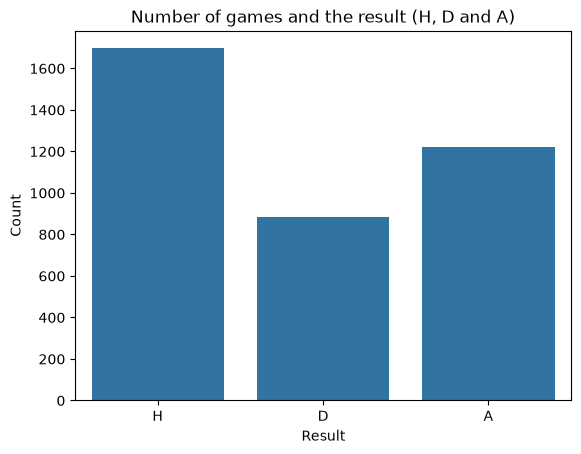

In [10]:
sns.countplot(x = 'FTR', data = df)                           #to check in a graph
plt.title('Number of games and the result (H, D and A)')
plt.xlabel('Result')
plt.ylabel('Count')
plt.show()

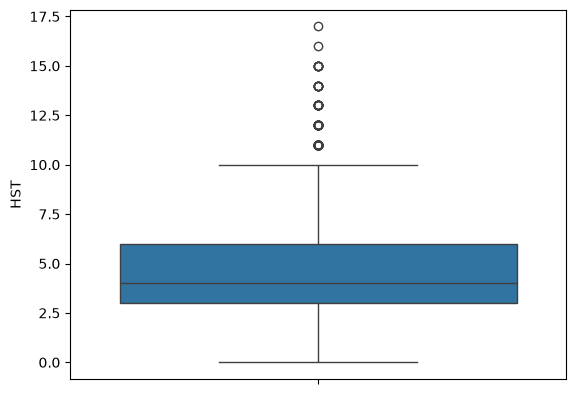

In [11]:
sns.boxplot(df['HST'])
plt.show()

In [12]:
#check outliers using IQR
Q1=df['HST'].quantile(0.25)     
Q3=df['HST'].quantile(0.75)     

IQR = Q3 - Q1                   
lower_bound = Q1 - 1.5 * IQR     
upper_bound = Q3 + 1.5 * IQR     

outliers = df[(df['HST'] < lower_bound) | (df['HST'] > upper_bound)]
print('lower bound:', lower_bound)
print('upper bound', upper_bound)
print ('number of outliers', len(outliers))

lower bound: -1.5
upper bound 10.5
number of outliers 110


- The boxplot shows that home teams that shot on target 11 or more times are outliers, but how it is a true result, it is not a fake match or a mistake of data, it will be kept in the analysis.

In [13]:
#For calculate correlation the result needs to be a number.
df['Result'] = df['FTR'].map({'A': 0, 'D': 1, 'H': 2})
print(df['Result'].value_counts())

Result
2    1696
0    1221
1     883
Name: count, dtype: int64


In [14]:
# Drop the column that I won't use, because these ones won't be used in the model (the goals show the match result) 
df_new = df.drop(['FTHG', 'FTAG', 'HTHG', 'HTAG'], axis = 1)

# axis = 1 means along columnwise

In [ ]:
df_number = df_new.select_dtypes(include=['float64', 'int64'])

correlation_matrix = df_number.corr()

# Set up the matplotlib figure
plt.figure(figsize=(10, 10))

# Create a heatmap with the correlation matrix
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, cbar_kws={"shrink": .8})

# Set the title
plt.title('Heatmap of Correlation Matrix for the Premier League Dataset')

# Show the plot
plt.show()

- Analysing the heatmap, where there are the biggest correlation with the result of the matches, affecting the results in a strong way, are the shots on target (AST and HST), followed by regular shots (HS and AS), while cards, corners and fouls don't have a strong influence
- The goals were excluded because the result of the match is decided by the goals. (The team that scores more goals wins), so these ones won't be used like a feature.